# Lab 2 — Models, sampling and estimation

**Lecture connections: weeks 4–5, building on week 3.**

Explain how a probability model represents a process, why sample means vary less than individuals,
and what a confidence interval says about an unknown population mean.

**Activities**

1. Match a model to a process
2. Calculate and simulate count probabilities
3. Interpret continuous densities and probabilities
4. Compare individual values with sample means
5. Estimate a mean and investigate interval coverage
6. Explain your conclusions

Run cells in order with **Shift+Enter**. Predict, run, then explain the change in statistical terms.
All code is supplied. Further investigations after the exit task are optional.

## 1. Choose a model

**Week 4: choose from the process and support, then examine fit.**

| Process | Model and parameters | Key assumption |
|---|---|---|
| Defaults among $m$ loans | Binomial $(m,p)$ | Fixed number of independent loans with a common probability |
| Calls in one hour | Poisson $(\lambda)$ | Constant-rate process with independent increments |
| Trial of the first success | Geometric $(p)$, starting at 1 | Independent trials with the same success probability |
| Time until the next call | Exponential, mean $1/\lambda$ | A homogeneous Poisson arrival process |
| A value in a bounded interval | Uniform $(a,b)$ | Equal probability for equal-width intervals |
| Symmetric measurement errors | Normal $(\mu,\sigma^2)$ | A bell-shaped distribution on the real line |
| Positive multiplicative outcomes | Log-normal $(\mu_{\log},\sigma_{\log})$ | The logarithm follows a normal distribution |

**Discuss:** Why could dependence among loans change a default-count distribution even if each
loan still has probability 0.02? Which of the models can represent a negative balance?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Open the notebook from its own folder or from the repository root.
DATA = Path('.') if Path('bank-marketing.csv').exists() else Path('Lab2')
if not (DATA / 'bank-marketing.csv').exists():
    raise FileNotFoundError('Open this notebook from Lab2 or the repository root.')
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
pd.set_option('display.max_columns', 12)

## 2. Count probabilities

**Weeks 3–4: a PMF gives probability at an integer; a CDF accumulates probability.**
For $X\sim\mathrm{Binomial}(50,0.02)$, predict the expected number of defaults and whether
$P(X\geq2)$ is larger than $P(X=2)$. Then compare exact probabilities with simulated frequencies.

,exact,simulation
P(X = 2),0.185801,0.18630
P(X <= 2),0.921572,0.92125
P(X >= 2),0.264229,0.26505


E(X) = 1.000; Var(X) = 0.980


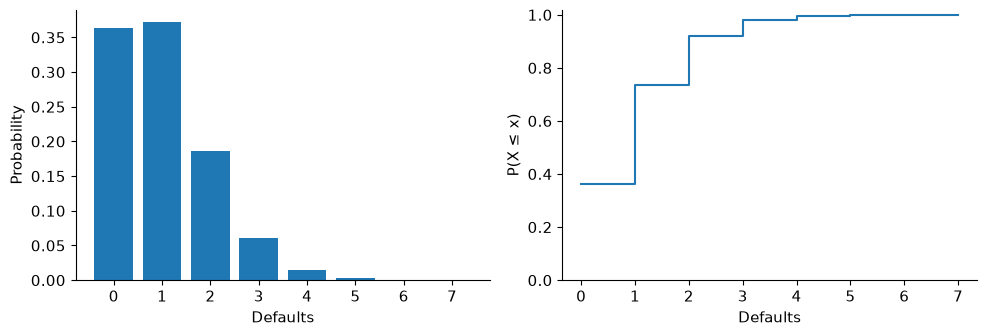

In [2]:
m, p = 50, 0.02  # Change m or p, and rerun this cell.
count_model = stats.binom(m, p)
rng = np.random.default_rng(204)
counts = rng.binomial(m, p, size=20000)
display(pd.DataFrame({
    'exact': [count_model.pmf(2), count_model.cdf(2), count_model.sf(1)],
    'simulation': [(counts == 2).mean(), (counts <= 2).mean(), (counts >= 2).mean()]
}, index=['P(X = 2)', 'P(X <= 2)', 'P(X >= 2)']))
print(f'E(X) = {m*p:.3f}; Var(X) = {m*p*(1-p):.3f}')

k = np.arange(0, int(count_model.ppf(0.9999)) + 2)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(k, count_model.pmf(k), label='Exact PMF')
axes[0].set(xlabel='Defaults', ylabel='Probability')
axes[1].step(k, count_model.cdf(k), where='post')
axes[1].set(xlabel='Defaults', ylabel='P(X ≤ x)', ylim=(0, 1.02))
plt.tight_layout()
plt.show()

In [3]:
# Ten calls per hour is a stipulated model, not an estimate from bank records.
arrival_rate = 10
display(pd.Series({
    'P(at least 12 calls in one hour)': stats.poisson.sf(11, arrival_rate),
    'P(no call in 6 minutes)': stats.poisson.pmf(0, arrival_rate * 6/60),
    'P(wait more than 6 minutes)': stats.expon.sf(6, scale=60/arrival_rate),
    'P(first success on trial 3), p=0.2': stats.geom.pmf(3, 0.2)
}))

P(at least 12 calls in one hour)      0.303224
P(no call in 6 minutes)               0.367879
P(wait more than 6 minutes)           0.367879
P(first success on trial 3), p=0.2    0.128000
dtype: float64

<details>
<summary>Check your reasoning</summary>

$E(X)=1$ and $\mathrm{Var}(X)=0.98$. “At least two” includes two, three and all larger counts,
so use `sf(1)` because `sf(k)` means $P(X>k)$. The CDF is a step function for an integer variable.
Under the stated arrival process, no calls during six minutes is the same event as a waiting time
longer than six minutes. The rate must use units consistent with the time interval.

</details>

## 3. Continuous probability is an area

**Week 4: normal and log-normal models.** Suppose settlement errors follow $N(0,2^2)$ euros.
Predict $P(-2\leq X\leq2)$. The density at 0 is a height; interval probabilities are areas.
A continuous model assigns zero probability to an exact value.

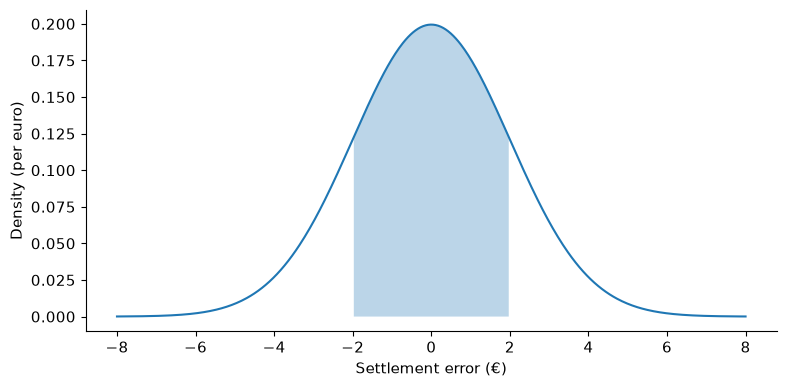

Interval probability: 0.6826894921370859
Upper 5% cutoff (€): 3.2897072539029444


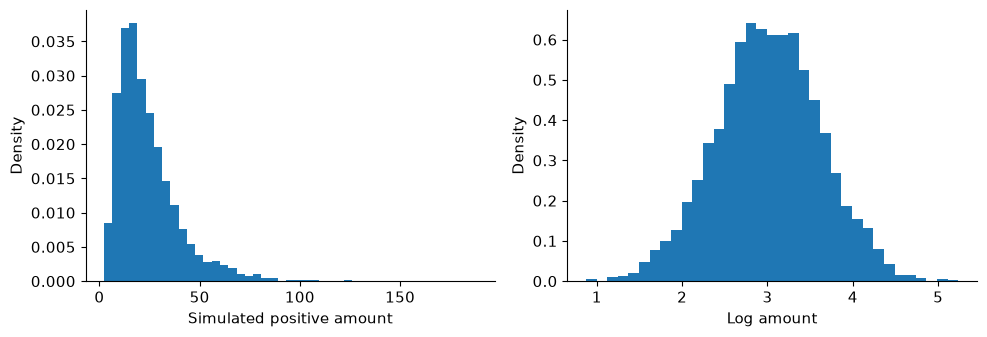

Model mean = 24.05; median = 20.09


In [4]:
mu, sigma = 0, 2
lower, upper = -2, 2
x = np.linspace(-8, 8, 500)
density = stats.norm.pdf(x, loc=mu, scale=sigma)
plt.plot(x, density)
plt.fill_between(x, density, where=(x >= lower) & (x <= upper), alpha=0.3)
plt.xlabel('Settlement error (€)')
plt.ylabel('Density (per euro)')
plt.tight_layout()
plt.show()
print('Interval probability:', stats.norm.cdf(upper, mu, sigma) - stats.norm.cdf(lower, mu, sigma))
print('Upper 5% cutoff (€):', stats.norm.ppf(0.95, mu, sigma))

# If log(Y) is Normal(mu_log, sigma_log²), then Y is log-normal.
mu_log, sigma_log = 3.0, 0.6
model = stats.lognorm(s=sigma_log, scale=np.exp(mu_log))
rng = np.random.default_rng(205)
y = rng.lognormal(mu_log, sigma_log, size=5000)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(y, bins=45, density=True)
axes[0].set(xlabel='Simulated positive amount', ylabel='Density')
axes[1].hist(np.log(y), bins=35, density=True)
axes[1].set(xlabel='Log amount', ylabel='Density')
plt.tight_layout()
plt.show()
print(f'Model mean = {model.mean():.2f}; median = {model.median():.2f}')

**Discuss:** Increase $\sigma_{\log}$ from 0.6 to 1.0. Which changes more, the mean or median?
Why is a log-normal model unsuitable for the full balance column, which includes zero and negative values?

<details>
<summary>Check your reasoning</summary>

The normal interval has probability about 0.683. With fixed $\mu_{\log}$, the log-normal
median stays at $e^{\mu_{\log}}$ while its mean increases as $e^{\mu_{\log}+\sigma_{\log}^2/2}$.
Its support is strictly positive. A log transformation must be justified for the measurement and its support.

</details>

## 4. Sampling distributions and standard errors

**Week 4: the central limit theorem concerns the mean across repeated samples.**
Use all 45,211 UCI bank balances as a finite reference population. Draw records independently
with replacement to study sampling variation under this explicit model.
This experiment's target is the mean of the file.

**Predict:** When sample size increases fourfold, what happens to the SD of individual balances?
What happens to the standard error of a sample mean?

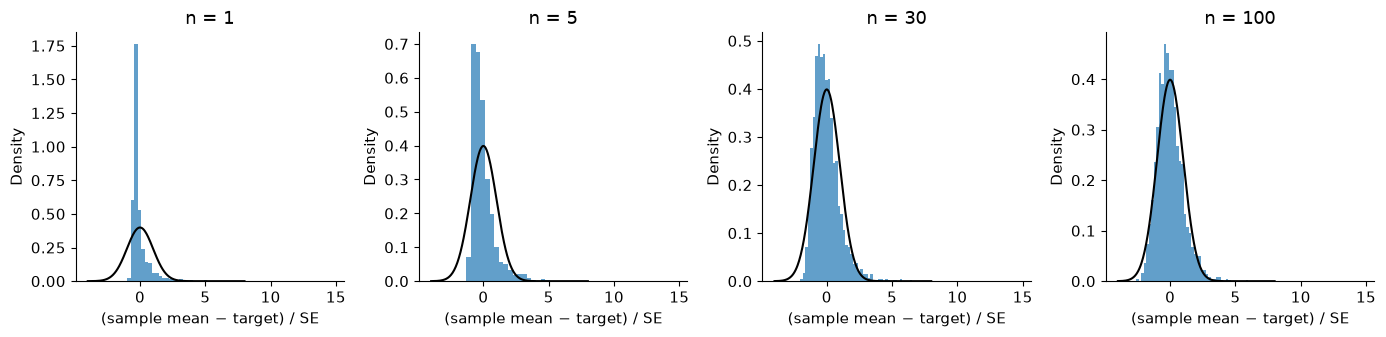

,n,mean of means,empirical SE,SD / sqrt(n)
0,1,1306.68,2619.85,3044.73
1,5,1363.87,1452.89,1361.65
2,30,1354.66,536.55,555.89
3,100,1357.92,299.13,304.47


Reference mean €1362.27; SD of individuals €3044.73


In [5]:
balances = pd.read_csv(DATA / 'bank-marketing.csv')['balance'].to_numpy()
population_mean, population_sd = balances.mean(), balances.std(ddof=0)
rng = np.random.default_rng(206)
sample_sizes = [1, 5, 30, 100]
sampling_results = []
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharex=True)
for ax, n in zip(axes, sample_sizes):
    means = rng.choice(balances, size=(3000, n), replace=True).mean(axis=1)
    se = population_sd / np.sqrt(n)
    # Use the same standardised scale to compare shapes, not just widths.
    ax.hist((means - population_mean) / se, bins=45, density=True, alpha=0.7)
    z_grid = np.linspace(-4, 8, 300)
    ax.plot(z_grid, stats.norm.pdf(z_grid), color='black')
    ax.set(title=f'n = {n}', xlabel='(sample mean − target) / SE', ylabel='Density')
    sampling_results.append([n, means.mean(), means.std(ddof=1), se])
plt.tight_layout()
plt.show()
display(pd.DataFrame(sampling_results, columns=['n', 'mean of means', 'empirical SE', 'SD / sqrt(n)']).round(2))
print(f'Reference mean €{population_mean:.2f}; SD of individuals €{population_sd:.2f}')

**Discuss:** Does n = 30 remove the long tail in this example? Compare the empirical and theoretical
standard errors. Distinguish the repeated fixed-size samples here from Lab 1's single growing sample.

<details>
<summary>Check your reasoning</summary>

Individual balances retain the same distribution. For independent draws, quadrupling n halves
the theoretical SE. Skewness and rare extreme balances can make the normal approximation slow;
30 is not a universal threshold. The law of large numbers concerns concentration around the target,
while the CLT describes the limiting shape after centring and scaling. Neither establishes a representative sampling design.

</details>

**Your response:** Explain SD, SE and the CLT in three sentences using the bank-balance experiment.

## 5. Confidence intervals and coverage

**Week 5: point estimate ± critical value × estimated SE.**
The office-minutes dataset contains 200 reported daily times spent locating misplaced
items, consistent with an Accountemps survey scenario. Estimate the mean time for a population
represented by independent, comparable observations.

The population SD is unknown, so use $\bar x\pm t_{n-1,0.975}s/\sqrt n$.
At this sample size the t and normal cutoffs are close; choosing t follows how the SD is obtained.

n                 200.000
mean (minutes)     49.800
SD (minutes)       15.992
SE (minutes)        1.131
lower CI           47.570
upper CI           52.030
dtype: float64

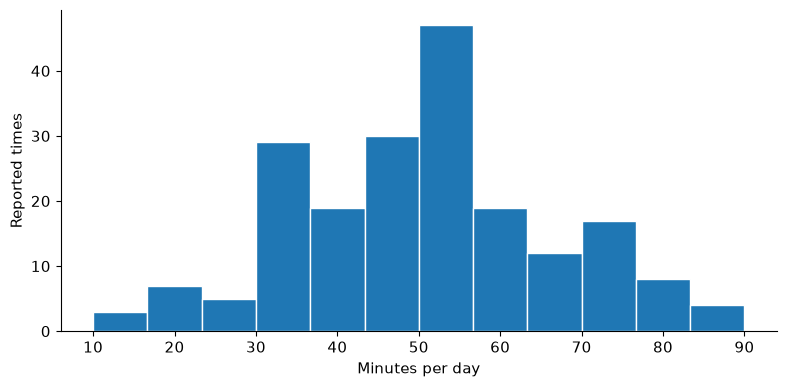

In [6]:
minutes = pd.read_csv(DATA / 'office-minutes.csv')['Minutes']
n = len(minutes)
mean_minutes, s = minutes.mean(), minutes.std(ddof=1)
se = s / np.sqrt(n)
confidence = 0.95  # Try 0.90 and 0.99, predicting the change in width first.
t_critical = stats.t.ppf((1 + confidence) / 2, df=n - 1)
office_ci = (mean_minutes - t_critical * se, mean_minutes + t_critical * se)
display(pd.Series({'n': n, 'mean (minutes)': mean_minutes, 'SD (minutes)': s,
                   'SE (minutes)': se, 'lower CI': office_ci[0], 'upper CI': office_ci[1]}).round(3))
minutes.plot.hist(bins=12, edgecolor='white')
plt.xlabel('Minutes per day')
plt.ylabel('Reported times')
plt.tight_layout()
plt.show()

Coverage in 2000 repeated samples: 0.952
Average interval width: 9.25 minutes


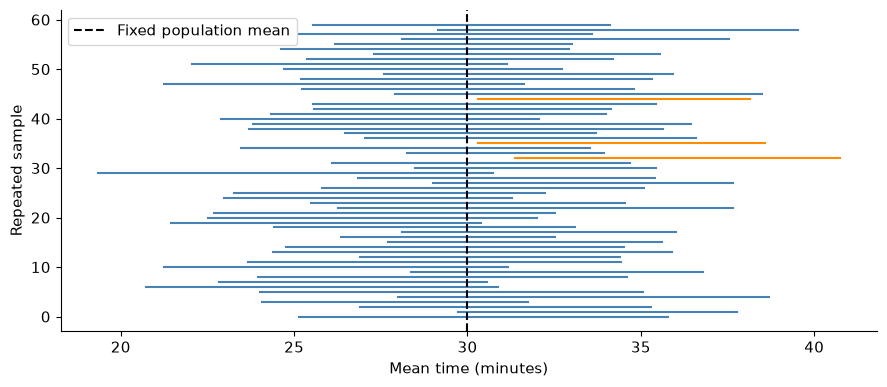

In [7]:
# In this separate normal-population experiment we know the target, so coverage can be checked.
rng = np.random.default_rng(207)
true_mu, true_sigma, n, repetitions = 30, 10, 20, 2000
confidence = 0.95
samples = rng.normal(true_mu, true_sigma, size=(repetitions, n))
means = samples.mean(axis=1)
estimated_se = samples.std(axis=1, ddof=1) / np.sqrt(n)
critical = stats.t.ppf((1 + confidence) / 2, df=n-1)
lo, hi = means - critical * estimated_se, means + critical * estimated_se
covers = (lo <= true_mu) & (true_mu <= hi)
print(f'Coverage in {repetitions} repeated samples: {covers.mean():.3f}')
print(f'Average interval width: {(hi-lo).mean():.2f} minutes')
fig, ax = plt.subplots(figsize=(9, 4))
for j in range(60):
    ax.plot([lo[j], hi[j]], [j, j], color='steelblue' if covers[j] else 'darkorange')
ax.axvline(true_mu, color='black', linestyle='--', label='Fixed population mean')
ax.set(xlabel='Mean time (minutes)', ylabel='Repeated sample')
ax.legend()
plt.tight_layout()
plt.show()

<details>
<summary>Check your reasoning</summary>

Confidence describes the long-run fraction of intervals covering the fixed population mean under
the sampling model. Increasing confidence widens each interval; increasing n generally narrows it.
The simulation fluctuates around its nominal coverage. A confidence interval for the mean is
different from an interval covering 95% of individuals. For the office data, the sampling design
determines which population the interval can describe.

</details>

## 6. Exit task

**Your response:** Report the office mean and interval with units. State why you used t,
interpret confidence, and explain why the SD of individual times is larger than the SE of their mean.

---

## Optional investigation A — Approximate discrete probabilities

**Week 4: continuity correction gives an integer count its full width.**
Compare the exact binomial lower tail with a normal approximation. For $P(X\leq k)$,
the corrected boundary is $k+0.5$. Inspect both a rare-event and a more symmetric case.

,m,p,k,exact,Poisson,normal,normal + correction
0,50,0.02,2,0.921572,0.919699,0.843789,0.935143
1,50,0.20,12,0.813943,0.791556,0.760250,0.811620
2,100,0.50,55,0.864373,0.784470,0.841345,0.864334


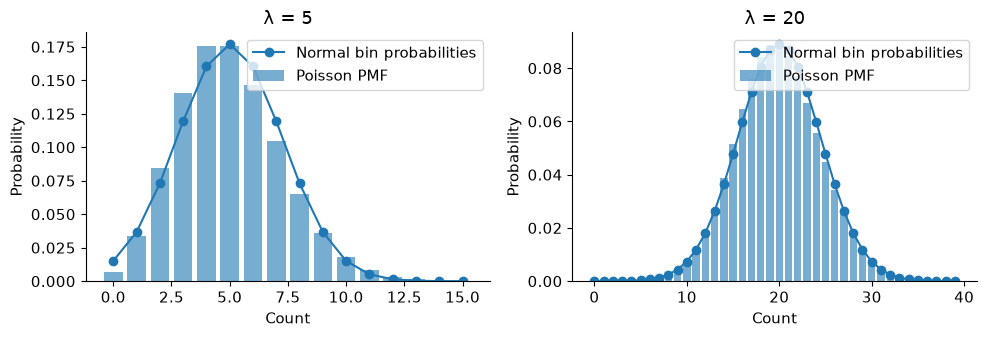

In [8]:
rows = []
for m, p, k in [(50, 0.02, 2), (50, 0.2, 12), (100, 0.5, 55)]:
    mu, sd = m*p, np.sqrt(m*p*(1-p))
    rows.append([m, p, k, stats.binom.cdf(k, m, p), stats.poisson.cdf(k, m*p),
                 stats.norm.cdf(k, mu, sd), stats.norm.cdf(k+0.5, mu, sd)])
display(pd.DataFrame(rows, columns=['m', 'p', 'k', 'exact', 'Poisson', 'normal', 'normal + correction']))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, rate in zip(axes, [5, 20]):
    k = np.arange(0, int(stats.poisson.ppf(0.9999, rate)) + 1)
    ax.bar(k, stats.poisson.pmf(k, rate), alpha=0.6, label='Poisson PMF')
    # Normal bin areas are comparable with integer probabilities.
    normal_bins = stats.norm.cdf(k+0.5, rate, np.sqrt(rate)) - stats.norm.cdf(k-0.5, rate, np.sqrt(rate))
    ax.plot(k, normal_bins, 'o-', label='Normal bin probabilities')
    ax.set(title=f'λ = {rate}', xlabel='Count', ylabel='Probability')
    ax.legend()
plt.tight_layout()
plt.show()

Check the approximation at the threshold that matters to the decision. Poisson works well for
rare independent binomial events; a normal approximation improves when a count is less skewed.
A close-looking centre does not guarantee accurate tail probabilities.

## Optional investigation B — CDFs and fitting parameters

**Weeks 3–4.** The empirical CDF at $x$ is the fraction of observations at or below $x$.
At the smallest distinct observation it starts at $1/n$ and at the largest it reaches 1.
Compare it with a fitted model, then discuss what a visual match can and cannot establish.

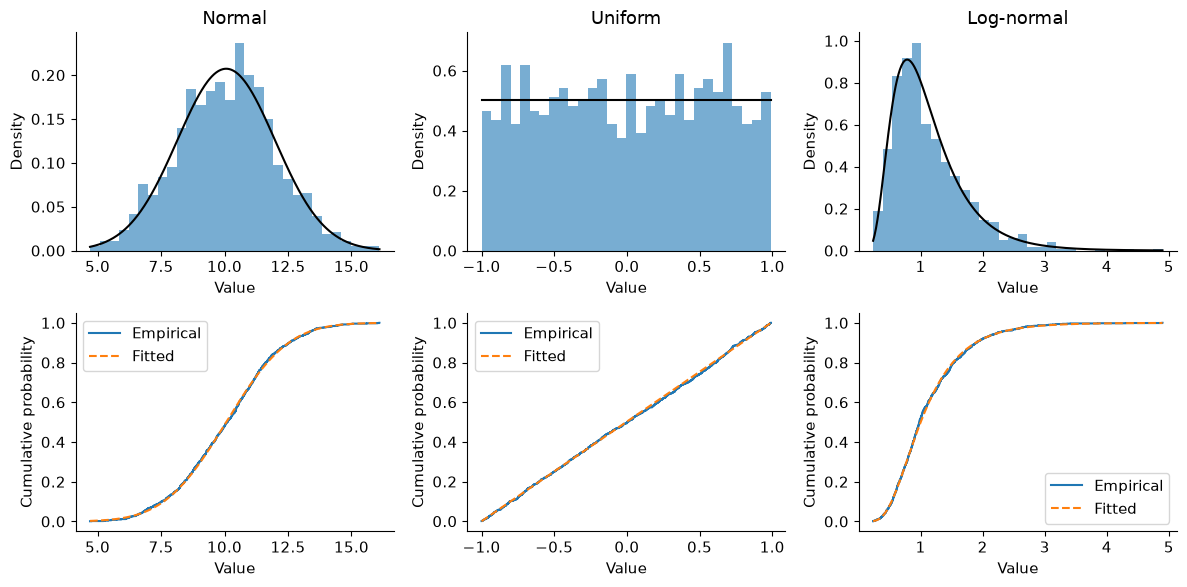

,true parameter,estimate
Geometric p (trials start at 1),0.2,0.203998
Binomial p (known m=10),0.3,0.304300
Poisson λ,3.0,3.009000


In [9]:
rng = np.random.default_rng(208)
normal_sample = rng.normal(10, 2, 1000)
uniform_sample = rng.uniform(-1, 1, 1000)
lognormal_sample = rng.lognormal(0, 0.5, 1000)
fitted = [stats.norm(*stats.norm.fit(normal_sample)),
          stats.uniform(*stats.uniform.fit(uniform_sample)),
          stats.lognorm(*stats.lognorm.fit(lognormal_sample, floc=0))]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for j, (values, model, name) in enumerate(zip([normal_sample, uniform_sample, lognormal_sample], fitted,
                                             ['Normal', 'Uniform', 'Log-normal'])):
    grid = np.linspace(values.min(), values.max(), 400)
    axes[0, j].hist(values, bins=30, density=True, alpha=0.6)
    axes[0, j].plot(grid, model.pdf(grid), color='black')
    axes[0, j].set(title=name, xlabel='Value', ylabel='Density')
    ordered = np.sort(values)
    axes[1, j].step(ordered, np.arange(1, len(values)+1)/len(values), where='post', label='Empirical')
    axes[1, j].plot(grid, model.cdf(grid), '--', label='Fitted')
    axes[1, j].set(xlabel='Value', ylabel='Cumulative probability')
    axes[1, j].legend()
plt.tight_layout()
plt.show()

# For these discrete models, the likelihood estimates have direct formulas.
geometric_sample = rng.geometric(0.2, 1000)
binomial_sample = rng.binomial(10, 0.3, 1000)
poisson_sample = rng.poisson(3, 1000)
display(pd.DataFrame({'true parameter': [0.2, 0.3, 3.0],
                      'estimate': [1/geometric_sample.mean(), binomial_sample.mean()/10, poisson_sample.mean()]},
                     index=['Geometric p (trials start at 1)', 'Binomial p (known m=10)', 'Poisson λ']))

## Optional investigation C — Log returns and multiplicative change

**Week 4: log-normal outcomes arise by exponentiating normal log changes.** Under the stated
geometric Brownian motion model, log increments are independent normal variables with mean
$(\mu-\sigma^2/2)\Delta t$ and SD $\sigma\sqrt{\Delta t}$.

Log changes add: $\log(S_1/S_0)+\log(S_2/S_1)=\log(S_2/S_0)$.
Simple returns compound: $(1+r_1)(1+r_2)-1$. This simulation illustrates the model's implications.

sum of log returns             -0.144084
log of final / initial price   -0.144084
compounded simple return       -0.134185
final / initial price - 1      -0.134185
dtype: float64

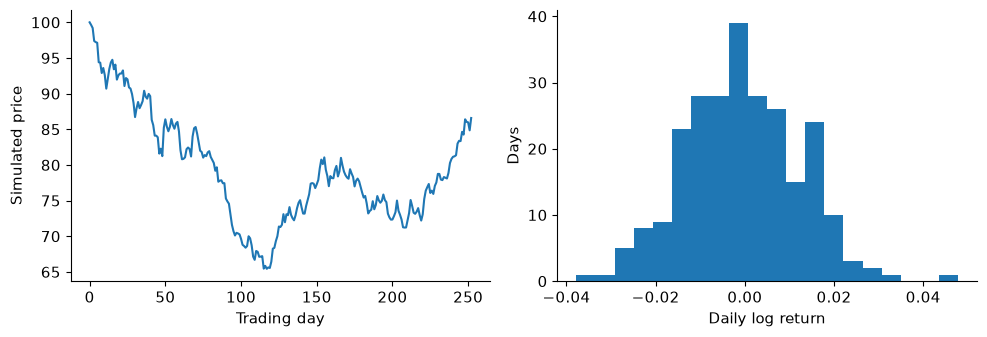

In [10]:
rng = np.random.default_rng(209)
mu, sigma, dt, steps = 0.08, 0.20, 1/252, 252
log_returns = (mu - sigma**2/2)*dt + sigma*np.sqrt(dt)*rng.standard_normal(steps)
prices = 100*np.exp(np.r_[0, np.cumsum(log_returns)])
simple_returns = np.expm1(log_returns)
display(pd.Series({'sum of log returns': log_returns.sum(),
                   'log of final / initial price': np.log(prices[-1]/prices[0]),
                   'compounded simple return': np.prod(1+simple_returns)-1,
                   'final / initial price - 1': prices[-1]/prices[0]-1}))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(np.arange(steps+1), prices)
axes[0].set(xlabel='Trading day', ylabel='Simulated price')
axes[1].hist(log_returns, bins=20)
axes[1].set(xlabel='Daily log return', ylabel='Days')
plt.tight_layout()
plt.show()

## Optional investigation D — Estimators and confidence intervals for proportions

**Week 5.** Compare a sample mean with the rule “sample mean + 10”. More data reduces sampling
variance, but the offset remains biased. Next examine a stipulated survey with 168 positive
responses among 200 independent respondents. The Wald interval uses the estimated probability
in its SE. Compare it with a Wilson interval when successes are scarce.

In [11]:
rng = np.random.default_rng(210)
rows = []
for n in [5, 30, 100]:
    means = rng.exponential(100, size=(3000, n)).mean(axis=1)
    for name, estimates in [('mean', means), ('mean + 10', means+10)]:
        rows.append([n, name, estimates.mean()-100, estimates.std(ddof=1), ((estimates-100)**2).mean()])
display(pd.DataFrame(rows, columns=['n', 'estimator', 'bias estimate', 'sampling SD', 'MSE']))

from statsmodels.stats.proportion import proportion_confint
for successes, n in [(168, 200), (1, 20)]:
    p_hat = successes/n
    estimated_se = np.sqrt(p_hat*(1-p_hat)/n)
    wald = p_hat + np.array([-1, 1])*stats.norm.ppf(0.975)*estimated_se
    wilson = proportion_confint(successes, n, alpha=0.05, method='wilson')
    print(f'{successes}/{n}: p̂={p_hat:.3f}, Wald={wald.round(3)}, Wilson={np.round(wilson, 3)}')
margin = 0.03
planned_n = int(np.ceil(stats.norm.ppf(0.975)**2 * 0.5*0.5 / margin**2))
print(f'Conservative normal-approximation sample-size plan for ±{margin:.0%}: {planned_n}')

,n,estimator,bias estimate,sampling SD,MSE
0,5,mean,0.915442,44.760229,2003.648305
1,5,mean + 10,10.915442,44.760229,2121.957139
2,30,mean,-0.216872,18.315541,335.394271
3,30,mean + 10,9.783128,18.315541,431.056823
4,100,mean,-0.223705,9.969664,99.411109
5,100,mean + 10,9.776295,9.969664,194.937002


168/200: p̂=0.840, Wald=[0.789 0.891], Wilson=[0.783 0.884]
1/20: p̂=0.050, Wald=[-0.046  0.146], Wilson=[0.009 0.236]
Conservative normal-approximation sample-size plan for ±3%: 1068


The Wald approximation can extend outside 0–1 when counts are small. Wilson intervals respect
the probability range. The sample-size calculation plans precision under independent sampling;
nonresponse, clustering and finite-population sampling require design-specific adjustments.

## Optional investigation E — Normal versus t and sampling without replacement

**Weeks 4–5.** Estimating the SD introduces additional uncertainty. Also, sampling a substantial
share of a finite population without replacement reduces sampling variance.

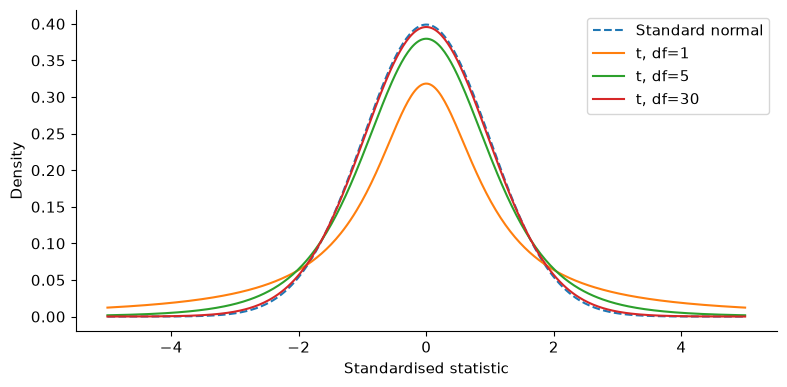

,df,two-sided 95% t cutoff,upper one-sided 5% t cutoff
0,5,2.570582,2.015048
1,30,2.042272,1.697261
2,199,1.971957,1.652547


With-replacement SE: 4.564; without-replacement SE: 3.553; simulated: 3.543


In [12]:
z = np.linspace(-5, 5, 400)
plt.plot(z, stats.norm.pdf(z), '--', label='Standard normal')
for df in [1, 5, 30]:
    plt.plot(z, stats.t.pdf(z, df), label=f't, df={df}')
plt.xlabel('Standardised statistic')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({'df': [5, 30, 199],
                      'two-sided 95% t cutoff': stats.t.ppf(0.975, [5, 30, 199]),
                      'upper one-sided 5% t cutoff': stats.t.ppf(0.95, [5, 30, 199])}))

rng = np.random.default_rng(211)
population = np.arange(1, 101)
N, n = len(population), 40
means = np.array([rng.choice(population, n, replace=False).mean() for _ in range(3000)])
se_replacement = population.std(ddof=0)/np.sqrt(n)
se_without = se_replacement*np.sqrt((N-n)/(N-1))
print(f'With-replacement SE: {se_replacement:.3f}; without-replacement SE: {se_without:.3f}; simulated: {means.std(ddof=1):.3f}')

## Data guide

`bank-marketing.csv`: all 45,211 `balance` values from `bank-full.csv`, in euros. Source: Moro, S., Rita, P. & Cortez, P. (2014),
[UCI Bank Marketing](https://doi.org/10.24432/C5K306), CC BY 4.0.

`office-minutes.csv`: 200 daily time measurements (`Minutes`) for the Accountemps survey
exercise. Use them to estimate the mean under the independent-sampling assumption; a claim
about a wider workforce also requires a representative sampling design.
All other observations in this notebook are simulations with the generating assumptions stated above.